In [37]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()

In [27]:
X = np.array([1, 2, 3, 4, 5])
y = np.array([3 ,5 ,7 ,9, 11])

w = 0
b = 0
learning_rate = 1 / 12

In [28]:
def predict(X, w ,b):
    return w * X + b

In [29]:
def mse(y, y_pred):
    return np.mean((y-y_pred) ** 2)

In [30]:
def gradients(X, y, y_pred):
    dw = 2 * (np.mean((y_pred - y) * X))
    db = 2 * (np.mean(y_pred - y))
    return dw, db

In [31]:
def train_loop(X, y, w, b, learning_rate):
    loss_history = []
    for _ in range(1000):
        y_pred = predict(X ,w ,b)
        mse_error = mse(y, y_pred)
        loss_history.append(float(mse_error))
        dw, db = gradients(X , y, y_pred)
        w = w - learning_rate * dw
        b = b - learning_rate * db
    y_pred = predict(X ,w ,b)
    mse_error = mse(y, y_pred)
    loss_history.append(float(mse_error))

    return loss_history

In [32]:
def plot_loss_history(loss_history):
    plt.plot(loss_history)
    plt.xlabel("Training step")
    plt.ylabel("Mse error")
    plt.title(f"MSE error during training, lr = {learning_rate}")
    plt.show()

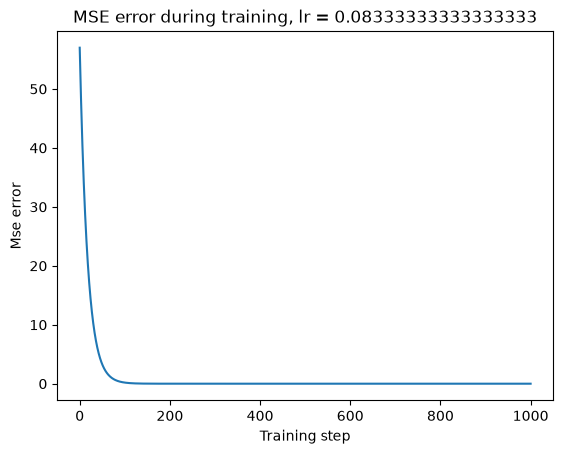

In [33]:
loss_history = train_loop(X ,y, w ,b, learning_rate)
plot_loss_history(loss_history)

# Comparing learning rates

In [34]:
def sns_plot_loss_history(ax, loss_history, learning_rate):
    x = range(len(loss_history))
    sns.lineplot(x = x, y = loss_history, ax = ax)
    ax.set_title(f"MSE error , lr = {learning_rate}")
    ax.set_xlabel("Training step")
    ax.set_ylabel("mse error")

In [35]:
learning_rates = np.array([0.01, 0.05, 0.084, 0.08456])

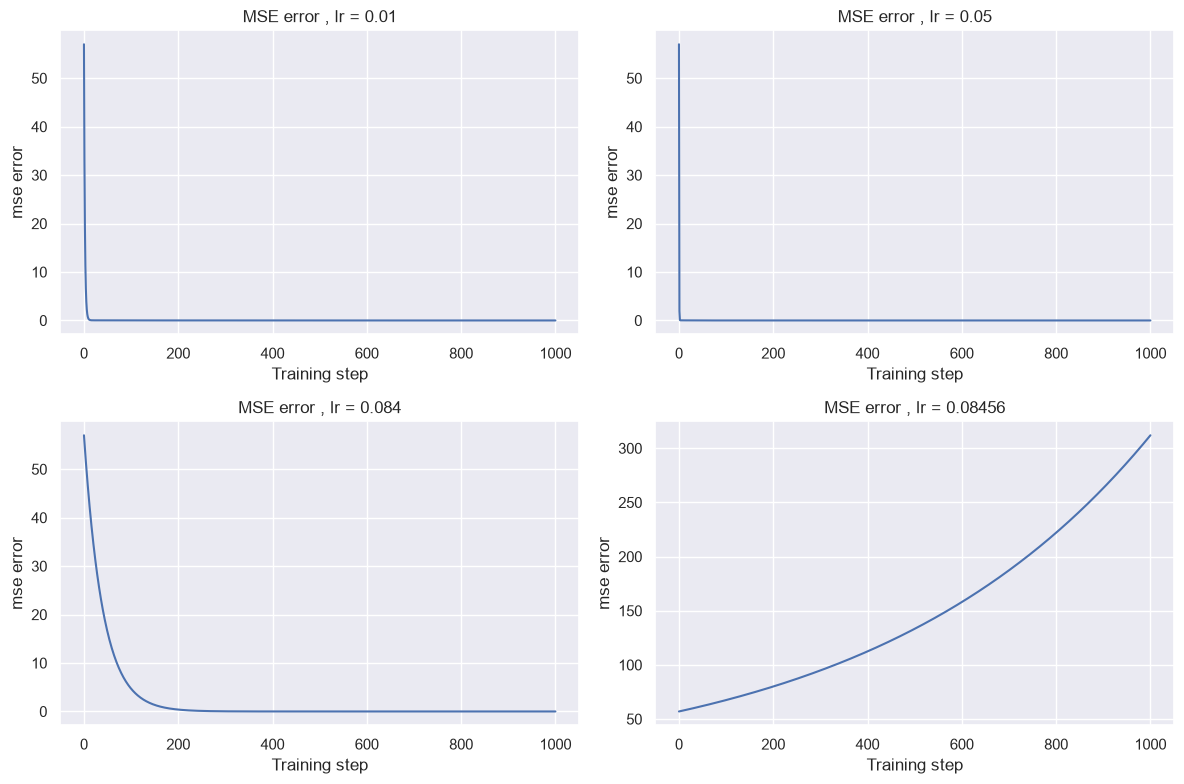

In [38]:
fig, axes = plt.subplots(2, 2, figsize = (12, 8))

for ax, lr in zip(axes.flat, learning_rates):
    w = 0
    b = 0
    learning_rate = lr

    loss_history = train_loop(X, y, w ,b, learning_rate)

    sns_plot_loss_history(ax, loss_history, lr)
plt.tight_layout()
plt.show()